# Fase 2 — EDA del mercado Airbnb en Río de Janeiro

Este notebook parte de `proy_airbnb_rio.clean.listings`. Los informes recibidos confirman una carga de 48 247 anuncios, 52 columnas, 44 147 precios positivos y 4 100 ausentes. La mediana anunciada es BRL 450, la media BRL 860,70 y el máximo BRL 587 008. Estos valores se recalculan al ejecutar.

**Preguntas:** ¿dónde se concentra la oferta?, ¿cómo varían los precios por barrio, tipo y capacidad?, ¿en qué segmentos falta precio?, ¿qué extremos requieren investigación?

## Ejecución

Guarda el archivo en `notebooks/`, selecciona el kernel de tu `.venv` y ejecuta las **10 celdas de código** en orden. No necesita paquetes nuevos respecto de los que ya instalaste. Los resultados se guardan en `reports/eda/`.

**Única escritura en PostgreSQL:** la celda 3 corrige el anuncio cuyo `bathrooms_text` dice exactamente `No bathroom` y cuyo baño derivado sigue siendo NULL. Lo cambia a 0, dentro de una transacción y con registro de auditoría. Si ya está corregido, no lo modifica. No crea, reemplaza ni elimina tablas; no modifica staging. El resto del análisis se hace en memoria y con lecturas.

Los gráficos y comparaciones no establecen causalidad ni prueban precios óptimos, rentabilidad, ocupación o demanda observadas. Todavía no se entrena ML ni se deciden exclusiones definitivas.

## 1. Preparar entorno, rutas y parámetros

El mínimo de 30 precios es una regla de presentación para evitar rankings basados en muy pocos anuncios; no es una garantía de representatividad ni un filtro para borrar filas.

In [1]:
import json
import sys
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from IPython.display import display

HOST, PORT = 'localhost', 5432
DATABASE, USER = 'proy_airbnb_rio', 'postgres'
RAIZ_MANUAL = ''
MIN_PRECIOS_RANKING = 30
TOP_BARRIOS = 15
if RAIZ_MANUAL:
    RAIZ = Path(RAIZ_MANUAL).expanduser().resolve()
else:
    inicio = Path.cwd().resolve()
    RAIZ = next((p for p in [inicio, *inicio.parents]
                 if (p / 'data' / 'raw').is_dir() and (p / 'src').is_dir()), None)
if RAIZ is None or not (RAIZ / 'data' / 'raw').is_dir():
    raise RuntimeError('Configura RAIZ_MANUAL con la carpeta principal del proyecto.')
REPORTES = RAIZ / 'reports' / 'eda'
FIGURAS = REPORTES / 'figuras'
FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
print('Python:', sys.executable)
print('Proyecto:', RAIZ)
print('Informes:', REPORTES)

Python: c:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model\.venv\Scripts\python.exe
Proyecto: C:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model
Informes: C:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model\reports\eda


## 2. Conectar y leer la capa limpia

Se conserva la conexión configurada para el ajuste de la celda siguiente. Las conexiones activas se cierran con cada bloque; el motor se libera en la última celda.

In [2]:
motor = create_engine(
    URL.create('postgresql+psycopg2', username=USER,
               password=getpass(f'Contraseña de {USER}: '), host=HOST,
               port=PORT, database=DATABASE),
    connect_args={'connect_timeout': 10}, pool_pre_ping=True,
)
try:
    with motor.connect() as conexion:
        with conexion.begin():
            conexion.execute(text('SET TRANSACTION READ ONLY'))
            df = pd.read_sql_query(text('SELECT * FROM clean.listings'), conexion)
except Exception:
    motor.dispose()
    raise
requeridas = {'id', 'host_id', 'price', 'price_currency', 'bathrooms_text', 'bathrooms_derived',
              'neighbourhood_cleansed', 'room_type', 'property_type', 'accommodates',
              'latitude', 'longitude', 'last_scraped', 'beds', 'bedrooms',
              'minimum_nights', 'maximum_nights', 'number_of_reviews', 'review_scores_rating'}
if not requeridas <= set(df.columns):
    raise ValueError(f'Faltan columnas de clean.listings: {sorted(requeridas - set(df.columns))}')
if df.empty or df['id'].isna().any() or df['id'].duplicated().any():
    raise ValueError('La tabla está vacía o tiene IDs ausentes/repetidos.')
print(f'Lectura: {len(df):,} anuncios, {df.shape[1]} columnas.')

Lectura: 48,247 anuncios, 52 columnas.


## 3. Cerrar el caso pendiente de baños: `No bathroom`

El parser anterior dejó este formato como desconocido. En este texto explícito corresponde 0 baños. Los 59 casos sin texto seguirán siendo NULL. Se exige como máximo un anuncio con ese texto, según el perfil recibido; una cantidad mayor detiene el ajuste para revisión.

Esta celda escribe solo el campo `bathrooms_derived` del ID comprobado. El informe histórico de la fase 1.2 no se sobrescribe. El registro del ajuste se añade a `reports/eda/ajustes_banos.jsonl`.

In [3]:
ajustes_banos = []
try:
    with motor.begin() as conexion:
        casos = conexion.execute(text("""
            SELECT id, bathrooms_derived
            FROM clean.listings
            WHERE LOWER(BTRIM(bathrooms_text)) = 'no bathroom'
            FOR UPDATE
        """)).mappings().all()
        if len(casos) > 1:
            raise RuntimeError('Apareció más de un No bathroom. Revisar antes de ajustar.')
        for caso in casos:
            if caso['bathrooms_derived'] is None:
                n = conexion.execute(text("""
                    UPDATE clean.listings SET bathrooms_derived = 0
                    WHERE id = :id AND bathrooms_derived IS NULL
                      AND LOWER(BTRIM(bathrooms_text)) = 'no bathroom'
                """), {'id': caso['id']}).rowcount
                if n != 1:
                    raise RuntimeError('El ajuste no afectó exactamente un anuncio; se revierte.')
                ajustes_banos.append({'id': str(caso['id']), 'antes': None, 'despues': 0,
                                      'regla': 'No bathroom explícito equivale a 0 baños'})
            elif float(caso['bathrooms_derived']) != 0:
                raise RuntimeError('No bathroom tiene un valor derivado inesperado. Revisar.')
    if ajustes_banos:
        with (REPORTES / 'ajustes_banos.jsonl').open('a', encoding='utf-8') as salida:
            for ajuste in ajustes_banos:
                registro = {'generado_utc': datetime.now(timezone.utc).isoformat(), **ajuste}
                salida.write(json.dumps(registro, ensure_ascii=False) + chr(10))
    with motor.connect() as conexion:
        with conexion.begin():
            conexion.execute(text('SET TRANSACTION READ ONLY'))
            df = pd.read_sql_query(text('SELECT * FROM clean.listings'), conexion)
except Exception:
    motor.dispose()
    raise
print('Ajustes aplicados en esta ejecución:', len(ajustes_banos))
print('Baños derivados todavía ausentes:', int(df['bathrooms_derived'].isna().sum()))

Ajustes aplicados en esta ejecución: 1
Baños derivados todavía ausentes: 59


## 4. Definir las poblaciones y las métricas

**Oferta:** todos los anuncios. **Precios:** anuncios con precio positivo. Los porcentajes de cobertura usan toda la oferta, para mostrar dónde falta información. La exclusión de anuncios sin precio de las estadísticas de precio puede limitar su representatividad; no se interpreta como menor actividad.

`last_scraped` es fecha de recopilación. Las siete fechas de este corte no constituyen una serie histórica de precios.

In [4]:
datos = df.copy()
for c in ['price', 'latitude', 'longitude', 'accommodates', 'bedrooms', 'beds',
          'bathrooms_derived', 'minimum_nights', 'maximum_nights', 'number_of_reviews', 'review_scores_rating']:
    datos[c] = pd.to_numeric(datos[c], errors='coerce').astype(float)
monedas = datos['price_currency'].dropna().astype(str).unique().tolist()
if monedas != ['BRL'] or datos['price_currency'].isna().any():
    raise ValueError(f'Revisar unidades antes de comparar precios. Monedas encontradas: {monedas}')
datos['precio_analizable'] = datos['price'].gt(0) & np.isfinite(datos['price'])
for c in ['neighbourhood_cleansed', 'room_type', 'property_type']:
    datos[c] = datos[c].astype('string').fillna('<SIN DATO>')
datos['grupo_capacidad'] = pd.cut(datos['accommodates'],
    bins=[0, 2, 4, 6, 8, np.inf], labels=['1-2', '3-4', '5-6', '7-8', '9+']).astype('string').fillna('<SIN DATO>')
precios = datos.loc[datos['precio_analizable']].copy()
if precios.empty:
    raise ValueError('No hay precios positivos para analizar.')
fechas = pd.to_datetime(datos['last_scraped'], errors='coerce')
metricas = {
    'generado_utc': datetime.now(timezone.utc).isoformat(),
    'origen': 'clean.listings', 'moneda': 'BRL',
    'anuncios': len(datos), 'anuncios_con_precio_positivo': len(precios),
    'anuncios_sin_precio': int(datos['price'].isna().sum()),
    'cobertura_precio_pct': float(100 * len(precios) / len(datos)),
    'barrios': int(datos['neighbourhood_cleansed'].nunique()),
    'identificadores_anfitrion': int(datos['host_id'].nunique()),
    'precio_minimo': float(precios['price'].min()),
    'precio_mediana': float(precios['price'].median()),
    'precio_media': float(precios['price'].mean()),
    'precio_p99': float(precios['price'].quantile(.99)),
    'precio_maximo': float(precios['price'].max()),
    'raspado_desde': str(fechas.min().date()), 'raspado_hasta': str(fechas.max().date()),
    'banos_derivados_ausentes': int(datos['bathrooms_derived'].isna().sum()),
    'ajustes_banos_en_esta_ejecucion': len(ajustes_banos),
    'minimo_precios_para_ranking': MIN_PRECIOS_RANKING,
}
display(pd.Series(metricas).to_frame('resultado'))

def resumen_segmento(columnas):
    base = datos.assign(precio_estadistico=datos['price'].where(datos['precio_analizable']))
    t = base.groupby(columnas, observed=True, dropna=False).agg(
        anuncios=('id', 'size'), anfitriones=('host_id', 'nunique'),
        precios_disponibles=('precio_estadistico', 'count'),
        precio_mediana=('precio_estadistico', 'median'),
        precio_media=('precio_estadistico', 'mean'),
        precio_p25=('precio_estadistico', lambda s: s.quantile(.25)),
        precio_p75=('precio_estadistico', lambda s: s.quantile(.75)),
    ).reset_index()
    t['porcentaje_oferta'] = 100 * t['anuncios'] / len(datos)
    t['porcentaje_sin_precio'] = 100 * (1 - t['precios_disponibles'] / t['anuncios'])
    t['suficientes_precios_para_ranking'] = t['precios_disponibles'].ge(MIN_PRECIOS_RANKING)
    return t.sort_values('anuncios', ascending=False).reset_index(drop=True)

def guardar_figura(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIGURAS / nombre, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

,resultado
generado_utc,2026-11-21T19:48:23.160784+00:00
origen,clean.listings
moneda,BRL
anuncios,48247
anuncios_con_precio_positivo,44147
anuncios_sin_precio,4100
cobertura_precio_pct,91.502062
barrios,156
identificadores_anfitrion,26869
precio_minimo,18.97


## 5. Composición de la oferta y cobertura del precio

Se resumen todos los barrios y tipos. Los gráficos muestran los barrios con más anuncios. Revisa también `porcentaje_sin_precio`: un ranking de precios necesita conocer esa cobertura.

,neighbourhood_cleansed,anuncios,anfitriones,precios_disponibles,precio_mediana,precio_media,precio_p25,precio_p75,porcentaje_oferta,porcentaje_sin_precio,suficientes_precios_para_ranking
0,Copacabana,14938,8198,13669,457.50,824.47,341.60,688.00,30.96,8.50,True
1,Ipanema,3887,2177,3564,750.00,1123.37,525.00,1167.12,8.06,8.31,True
2,Barra da Tijuca,3709,2332,3332,642.00,1312.50,442.82,1012.32,7.69,10.16,True
3,Centro,3282,1900,3085,285.00,401.47,223.50,374.00,6.80,6.00,True
4,Recreio dos Bandeirantes,2511,1752,2352,439.66,699.64,280.00,716.50,5.20,6.33,True
5,Jacarepaguá,2081,1458,1922,472.58,717.00,309.00,847.62,4.31,7.64,True
6,Botafogo,2051,1491,1814,395.75,572.90,283.37,575.83,4.25,11.56,True
7,Leblon,1931,1195,1730,818.50,1292.55,571.12,1176.46,4.00,10.41,True
8,Santa Teresa,1660,1063,1546,300.00,564.06,205.00,490.00,3.44,6.87,True
9,Flamengo,1005,816,904,400.00,593.26,300.00,591.25,2.08,10.05,True


,room_type,anuncios,anfitriones,precios_disponibles,precio_mediana,precio_media,precio_p25,precio_p75,porcentaje_oferta,porcentaje_sin_precio,suficientes_precios_para_ranking
0,Entire home/apt,39334,22843,36148,491.0,948.39,335.00,814.52,81.53,8.10,True
1,Private room,8310,5118,7455,290.0,481.95,191.21,471.00,17.22,10.29,True
2,Shared room,582,201,533,120.0,216.94,79.20,175.00,1.21,8.42,True
3,Hotel room,21,7,11,413.0,561.50,288.75,583.00,0.04,47.62,False


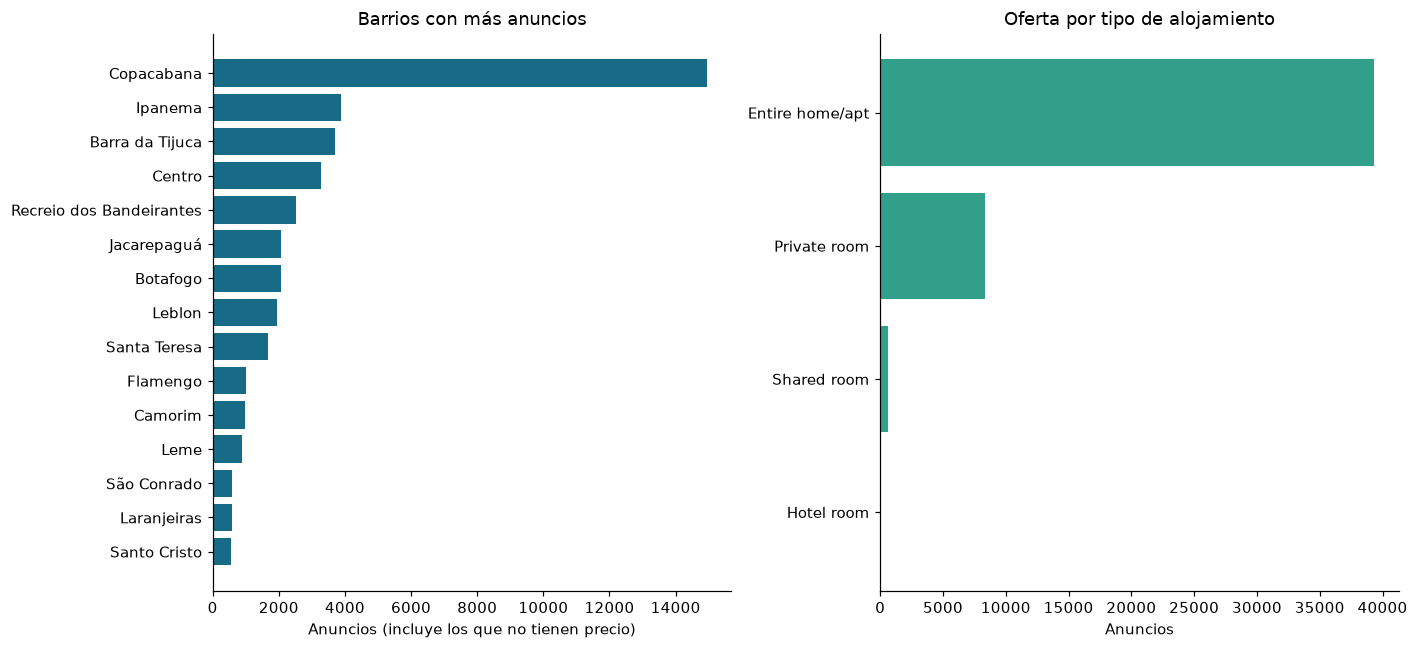

In [5]:
por_barrio = resumen_segmento(['neighbourhood_cleansed'])
por_tipo = resumen_segmento(['room_type'])
por_capacidad = resumen_segmento(['grupo_capacidad'])
display(por_barrio.head(15).round(2))
display(por_tipo.round(2))
fig, ejes = plt.subplots(1, 2, figsize=(13, 6))
top = por_barrio.head(TOP_BARRIOS).sort_values('anuncios')
ejes[0].barh(top['neighbourhood_cleansed'], top['anuncios'], color='#176B87')
ejes[0].set(title='Barrios con más anuncios', xlabel='Anuncios (incluye los que no tienen precio)')
tipos = por_tipo.sort_values('anuncios')
ejes[1].barh(tipos['room_type'], tipos['anuncios'], color='#329F8A')
ejes[1].set(title='Oferta por tipo de alojamiento', xlabel='Anuncios')
guardar_figura(fig, '01_composicion_oferta.png')

## 6. Distribución de precios y sensibilidad a los extremos

El primer gráfico usa todos los precios positivos en escala logarítmica. El segundo amplía la zona hasta el percentil 99 **solo para visualizar**. La comparación de sensibilidad no establece un filtro para el modelo ni elimina registros de PostgreSQL.

,escenario,anuncios,media,mediana
0,Todos los precios positivos,44147,860.7,450.0
1,Hasta P99; solo diagnóstico,43705,673.9,449.0


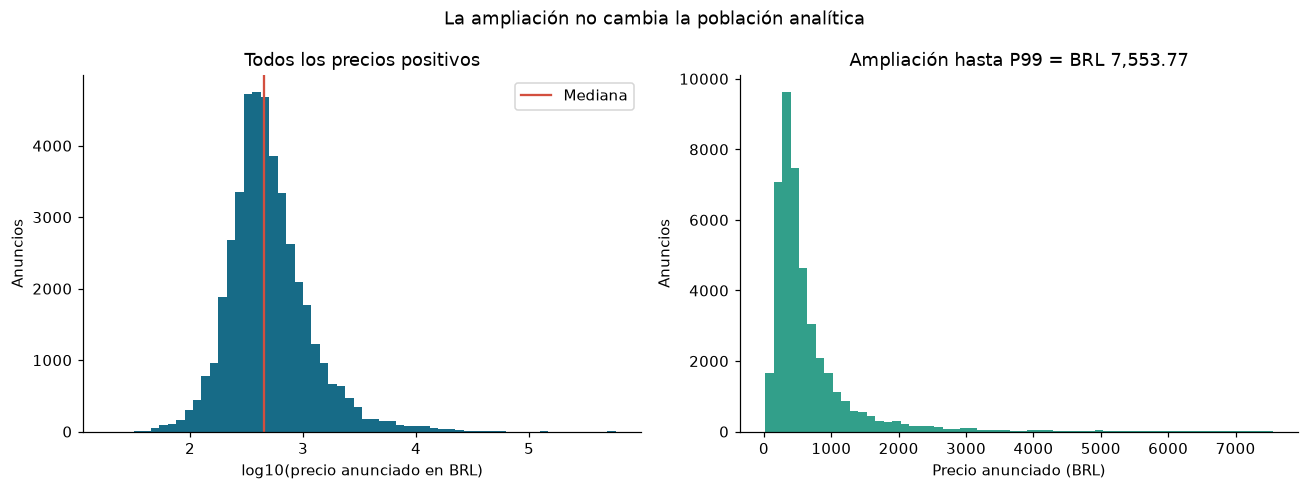

In [6]:
p99 = float(precios['price'].quantile(.99))
zona_central = precios.loc[precios['price'].le(p99), 'price']
sensibilidad = pd.DataFrame([
    {'escenario': 'Todos los precios positivos', 'anuncios': len(precios),
     'media': precios['price'].mean(), 'mediana': precios['price'].median()},
    {'escenario': 'Hasta P99; solo diagnóstico', 'anuncios': len(zona_central),
     'media': zona_central.mean(), 'mediana': zona_central.median()},
])
display(sensibilidad.round(2))
metricas['anuncios_por_encima_p99'] = int(precios['price'].gt(p99).sum())
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].hist(np.log10(precios['price']), bins=60, color='#176B87')
ejes[0].axvline(np.log10(precios['price'].median()), color='#D34F3F', label='Mediana')
ejes[0].set(title='Todos los precios positivos', xlabel='log10(precio anunciado en BRL)', ylabel='Anuncios')
ejes[0].legend()
ejes[1].hist(zona_central, bins=60, color='#329F8A')
ejes[1].set(title=f'Ampliación hasta P99 = BRL {p99:,.2f}', xlabel='Precio anunciado (BRL)', ylabel='Anuncios')
fig.suptitle('La ampliación no cambia la población analítica')
guardar_figura(fig, '02_distribucion_precios.png')

## 7. Comparar precios por segmentos

Las medianas por barrio mezclan diferentes tipos y capacidades. Para aproximar comparables se agrega también barrio + tipo + grupo de capacidad. Estas agrupaciones son descriptivas, todavía no son clusters de machine learning ni una valoración individual.

El ranking gráfico exige al menos 30 anuncios con precio en cada barrio. La tabla completa conserva todos los grupos. En el boxplot se ocultan los puntos extremos únicamente para facilitar la lectura.

,neighbourhood_cleansed,room_type,grupo_capacidad,anuncios,anfitriones,precios_disponibles,precio_mediana,precio_media,precio_p25,precio_p75,porcentaje_oferta,porcentaje_sin_precio,suficientes_precios_para_ranking
0,Copacabana,Entire home/apt,3-4,6688,4291,6190,433.74,701.98,350.00,583.00,13.86,7.45,True
1,Copacabana,Entire home/apt,5-6,2744,1884,2525,653.33,1065.51,470.00,968.50,5.69,7.98,True
2,Copacabana,Entire home/apt,1-2,2324,1658,2112,401.12,532.12,323.46,525.00,4.82,9.12,True
3,Ipanema,Entire home/apt,3-4,1796,1156,1639,745.67,1035.37,552.03,1094.00,3.72,8.74,True
4,Centro,Entire home/apt,3-4,1651,1079,1558,292.00,459.57,237.50,382.58,3.42,5.63,True
5,Barra da Tijuca,Entire home/apt,3-4,1608,1178,1435,616.50,798.98,473.42,824.00,3.33,10.76,True
6,Copacabana,Private room,1-2,1510,962,1325,280.00,394.90,202.50,430.00,3.13,12.25,True
7,Centro,Entire home/apt,1-2,990,622,922,283.55,312.63,221.15,349.30,2.05,6.87,True
8,Leblon,Entire home/apt,3-4,929,630,851,795.00,1205.41,587.16,1105.25,1.93,8.40,True
9,Recreio dos Bandeirantes,Entire home/apt,3-4,901,718,842,393.50,513.07,270.00,573.00,1.87,6.55,True


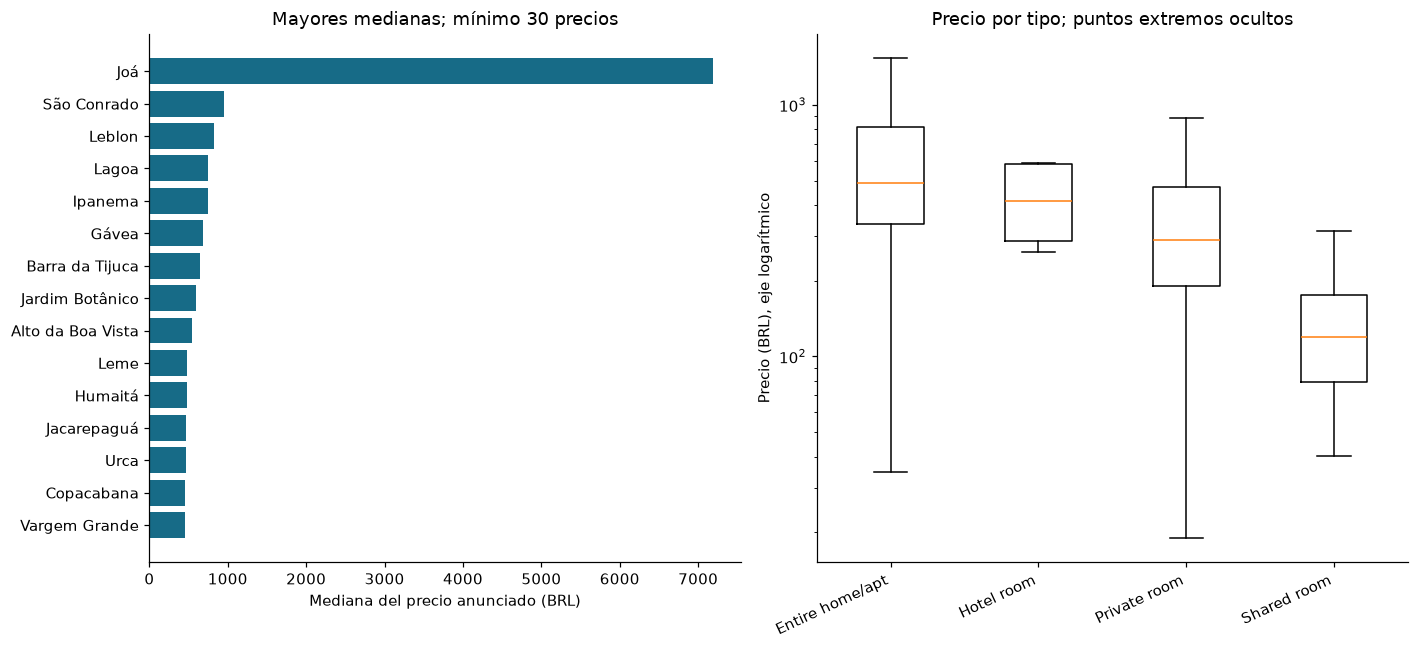

In [7]:
segmentos = resumen_segmento(['neighbourhood_cleansed', 'room_type', 'grupo_capacidad'])
display(segmentos.loc[segmentos['suficientes_precios_para_ranking']].head(20).round(2))
ranking_precio = por_barrio.loc[por_barrio['suficientes_precios_para_ranking']].sort_values('precio_mediana', ascending=False)
fig, ejes = plt.subplots(1, 2, figsize=(13, 6))
r = ranking_precio.head(TOP_BARRIOS).sort_values('precio_mediana')
if not r.empty:
    ejes[0].barh(r['neighbourhood_cleansed'], r['precio_mediana'], color='#176B87')
ejes[0].set(title=f'Mayores medianas; mínimo {MIN_PRECIOS_RANKING} precios', xlabel='Mediana del precio anunciado (BRL)')
grupos = list(precios.groupby('room_type', observed=True))
posiciones = list(range(1, len(grupos) + 1))
ejes[1].boxplot([g['price'].to_numpy() for _, g in grupos], positions=posiciones, showfliers=False)
ejes[1].set_xticks(posiciones)
ejes[1].set_xticklabels([str(nombre) for nombre, _ in grupos], rotation=25, ha='right')
ejes[1].set_yscale('log')
ejes[1].set(title='Precio por tipo; puntos extremos ocultos', ylabel='Precio (BRL), eje logarítmico')
guardar_figura(fig, '03_comparacion_precios.png')

## 8. Explorar la distribución geográfica

Cada hexágono resume anuncios cercanos: el primer panel cuenta toda la oferta con coordenadas utilizables y el segundo muestra la mediana de sus precios positivos. Las celdas espaciales con pocos anuncios pueden ser inestables; consulta también las tablas por barrio.

Si existe `data/raw/neighbourhoods.geojson`, se dibujan sus contornos como referencia. Dibujar contornos no comprueba que cada anuncio pertenezca al municipio ni valida la asignación de barrio. Son coordenadas geográficas, no un cálculo de áreas o distancias.

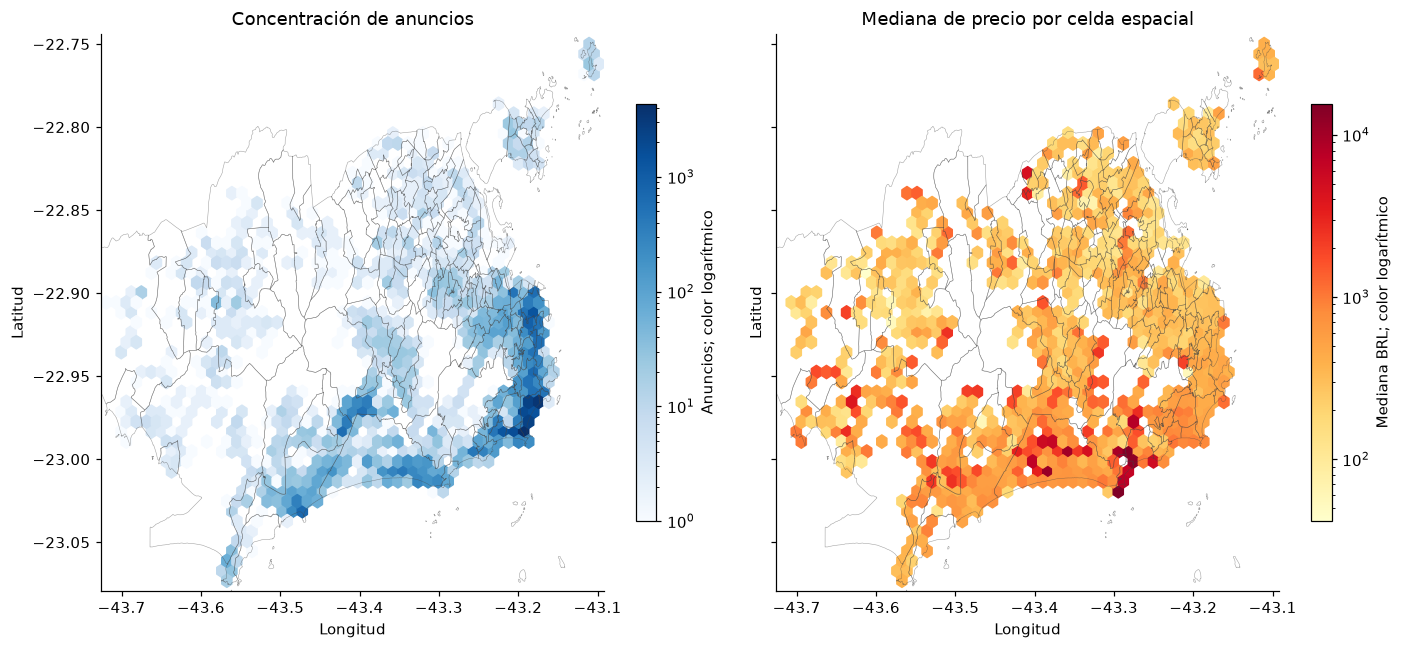

In [8]:
geo_valida = (datos['latitude'].between(-90, 90) & datos['longitude'].between(-180, 180)
              & np.isfinite(datos['latitude']) & np.isfinite(datos['longitude']))
geografia = datos.loc[geo_valida].copy()
geo_precio = geografia.loc[geografia['precio_analizable']].copy()
metricas['anuncios_sin_coordenadas_utilizables'] = int((~geo_valida).sum())
geojson_path = RAIZ / 'data' / 'raw' / 'neighbourhoods.geojson'
contornos = []
if geojson_path.is_file():
    try:
        geojson = json.loads(geojson_path.read_text(encoding='utf-8-sig'))
        for feature in geojson.get('features', []):
            geom = feature.get('geometry') or {}
            if geom.get('type') == 'Polygon':
                poligonos = [geom.get('coordinates', [])]
            elif geom.get('type') == 'MultiPolygon':
                poligonos = geom.get('coordinates', [])
            else:
                continue
            for poligono in poligonos:
                for anillo in poligono:
                    xy = np.asarray(anillo, dtype=float)
                    if xy.ndim == 2 and xy.shape[1] >= 2 and len(xy) > 2:
                        contornos.append(xy[:, :2])
    except (ValueError, TypeError, KeyError) as error:
        print('No se pudieron dibujar contornos:', error)
metricas['contornos_geojson_dibujados'] = len(contornos)
if geografia.empty or geo_precio.empty:
    print('No hay suficientes coordenadas para uno de los mapas; revisar los datos.')
else:
    fig, ejes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
    lon_min, lon_max = float(geografia['longitude'].min()), float(geografia['longitude'].max())
    lat_min, lat_max = float(geografia['latitude'].min()), float(geografia['latitude'].max())
    margen_lon = max((lon_max - lon_min) * .02, .001)
    margen_lat = max((lat_max - lat_min) * .02, .001)
    extension = (lon_min - margen_lon, lon_max + margen_lon,
                 lat_min - margen_lat, lat_max + margen_lat)
    h0 = ejes[0].hexbin(geografia['longitude'].to_numpy(), geografia['latitude'].to_numpy(),
                        gridsize=50, extent=extension, bins='log', mincnt=1, cmap='Blues')
    h1 = ejes[1].hexbin(geo_precio['longitude'].to_numpy(), geo_precio['latitude'].to_numpy(),
                        C=geo_precio['price'].to_numpy(), reduce_C_function=np.median,
                        gridsize=50, extent=extension, mincnt=1, norm=LogNorm(), cmap='YlOrRd')
    for ax in ejes:
        for xy in contornos:
            ax.plot(xy[:, 0], xy[:, 1], color='#444444', linewidth=.35, alpha=.5)
        ax.set(xlabel='Longitud', ylabel='Latitud', xlim=extension[:2], ylim=extension[2:])
    ejes[0].set_title('Concentración de anuncios')
    ejes[1].set_title('Mediana de precio por celda espacial')
    fig.colorbar(h0, ax=ejes[0], label='Anuncios; color logarítmico', shrink=.75)
    fig.colorbar(h1, ax=ejes[1], label='Mediana BRL; color logarítmico', shrink=.75)
    guardar_figura(fig, '04_distribucion_geografica.png')

## 9. Investigar alertas y anuncios extremos

Las reglas de capacidad pueden solaparse: no sumes sus conteos como si fueran anuncios distintos. Muchas camas o dormitorios pueden reflejar alojamientos colectivos o diferencias de publicación. Los 281 casos de noches marcados en la fase previa se desglosan aquí.

Se exportan los 50 precios más altos para revisar sus características y posibles comparables. Estar en esta lista no prueba que un anuncio sea erróneo.

In [9]:
reglas_revision = {
    'dormitorios_mayores_que_capacidad': datos['bedrooms'].gt(datos['accommodates']),
    'camas_mayores_que_capacidad': datos['beds'].gt(datos['accommodates']),
    'dormitorios_negativos': datos['bedrooms'].lt(0),
    'camas_negativas': datos['beds'].lt(0),
    'capacidad_ausente_o_menor_1': datos['accommodates'].isna() | datos['accommodates'].lt(1),
    'noches_minimas_ausentes': datos['minimum_nights'].isna(),
    'noches_maximas_ausentes': datos['maximum_nights'].isna(),
    'noches_minimas_mayores_que_maximas': datos['minimum_nights'].gt(datos['maximum_nights']),
    'noches_no_positivas': datos['minimum_nights'].lt(1) | datos['maximum_nights'].lt(1),
    'noches_maximas_mayores_365': datos['maximum_nights'].gt(365),
    'precio_por_encima_p99_global': datos['price'].gt(p99),
    'sin_valoracion_y_cero_resenas': datos['review_scores_rating'].isna() & datos['number_of_reviews'].eq(0),
    'sin_valoracion_y_con_resenas': datos['review_scores_rating'].isna() & datos['number_of_reviews'].gt(0),
}
revision_calidad = pd.DataFrame([{'regla': k, 'anuncios': int(v.fillna(False).sum())}
                                  for k, v in reglas_revision.items()])
revision_calidad['porcentaje_oferta'] = 100 * revision_calidad['anuncios'] / len(datos)
columnas_revision = ['id', 'neighbourhood_cleansed', 'room_type', 'property_type',
                     'accommodates', 'bedrooms', 'beds', 'bathrooms_derived',
                     'minimum_nights', 'maximum_nights', 'number_of_reviews', 'price']
extremos = precios.nlargest(50, 'price')[columnas_revision].copy()
display(revision_calidad.round(2))
display(extremos.head(15))

,regla,anuncios,porcentaje_oferta
0,dormitorios_mayores_que_capacidad,170,0.35
1,camas_mayores_que_capacidad,1360,2.82
2,dormitorios_negativos,0,0.00
3,camas_negativas,0,0.00
4,capacidad_ausente_o_menor_1,0,0.00
5,noches_minimas_ausentes,281,0.58
6,noches_maximas_ausentes,281,0.58
7,noches_minimas_mayores_que_maximas,0,0.00
8,noches_no_positivas,0,0.00
9,noches_maximas_mayores_365,12327,25.55


,id,neighbourhood_cleansed,room_type,property_type,accommodates,bedrooms,beds,bathrooms_derived,minimum_nights,maximum_nights,number_of_reviews,price
12124,695828287387937123,Copacabana,Entire home/apt,Entire rental unit,4.0,1.0,1.0,1.0,1.0,1125.0,0.0,587008.00
5958,30033272,Estácio,Entire home/apt,Entire rental unit,4.0,2.0,2.0,1.0,1.0,10.0,1.0,500120.00
11237,612328960110087884,Copacabana,Entire home/apt,Entire rental unit,10.0,1.0,8.0,1.0,1.0,1125.0,0.0,183338.00
17468,1020594041193205143,Itanhangá,Private room,Private room in rental unit,3.0,1.0,2.0,1.0,1.0,1125.0,0.0,160888.00
21625,1183192753413981844,Barra da Tijuca,Entire home/apt,Entire home,10.0,5.0,6.0,7.0,2.0,365.0,35.0,140250.00
47311,1765430048162852807,Centro,Entire home/apt,Entire home,4.0,1.0,1.0,1.0,1.0,365.0,0.0,132000.00
11241,612413603184031875,Copacabana,Entire home/apt,Entire rental unit,10.0,1.0,8.0,1.0,1.0,1100.0,0.0,116701.00
18576,1052324300244368019,Copacabana,Entire home/apt,Entire rental unit,6.0,2.0,3.0,1.5,6.0,15.0,2.0,100000.00
12126,695857334968550331,Copacabana,Entire home/apt,Entire rental unit,6.0,4.0,1.0,3.0,1.0,365.0,0.0,82624.00
17768,1031884804402365265,Copacabana,Entire home/apt,Entire rental unit,4.0,2.0,2.0,2.0,30.0,90.0,0.0,67346.18


## 10. Guardar resultados y cerrar conexiones

Las tablas se exportan completas, aunque los gráficos solo muestren algunos barrios. Los informes y figuras de EDA se reemplazan si repites el notebook; el registro de ajustes de baños se conserva por anexado.

Comparte `resumen_eda.json`, `eda_por_barrio.csv`, `eda_por_tipo.csv`, `eda_segmentos.csv`, `eda_revision_calidad.csv` y `eda_precios_extremos.csv`. Las figuras ayudan a discutir los hallazgos. A partir de esos resultados elegiremos las comparaciones del dashboard y definiremos el alcance del modelo de precios.

In [10]:
try:
    tablas = {
        'eda_por_barrio.csv': por_barrio,
        'eda_por_tipo.csv': por_tipo,
        'eda_por_capacidad.csv': por_capacidad,
        'eda_segmentos.csv': segmentos,
        'eda_sensibilidad_precios.csv': sensibilidad,
        'eda_revision_calidad.csv': revision_calidad,
        'eda_precios_extremos.csv': extremos,
    }
    for nombre, tabla in tablas.items():
        tabla.to_csv(REPORTES / nombre, index=False, encoding='utf-8-sig')
    (REPORTES / 'resumen_eda.json').write_text(
        json.dumps(metricas, ensure_ascii=False, indent=2), encoding='utf-8')
    print('EDA completado. Informes:', REPORTES)
    print('Figuras:', FIGURAS)
finally:
    motor.dispose()
print('Conexiones cerradas.')

EDA completado. Informes: C:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model\reports\eda
Figuras: C:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model\reports\eda\figuras
Conexiones cerradas.


## Cómo interpretar la entrega

El dashboard podrá separar volumen de oferta, cobertura de precios, medianas por segmentos y alertas de calidad. La disponibilidad del calendario no se interpreta como ocupación real. No se han eliminado precios extremos ni imputado variables para ML.

Antes de entrenar se fijará una estrategia para reservar un conjunto de evaluación y aprender imputaciones o transformaciones solo con entrenamiento. Las conclusiones del EDA sobre este corte completo son descriptivas; por sí solas no demuestran rendimiento predictivo en datos nuevos.

**Validación del archivo entregado:** sintaxis y operaciones analíticas revisadas con datos sintéticos. La conexión, el ajuste del anuncio y los resultados reales se verifican al ejecutarlo en tu equipo.

Documentación: [pandas groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html), [Matplotlib hexbin](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hexbin.html).